# Wrong-way detector — find objects moving against the flow with YOLO

This notebook takes a video, detects and tracks objects with **YOLO** (Ultralytics), works out the
**majority direction of motion**, and flags every object moving the **opposite way** — a wrong-way car,
a person walking against a crowd, a cyclist going against traffic, and so on.

**How it works**

1. **Detect + track** — YOLO finds objects in every frame and ByteTrack (or BoT-SORT) gives each one a persistent ID.
2. **Measure motion** — each track's centre is smoothed and turned into a velocity. Speed is measured in
   *box-diagonals per second*, so small far-away objects and large close-up ones are treated fairly. Objects slower than a threshold count as stationary.
3. **Find the majority direction** — every moving object casts one vote with its heading; the direction with the most
   supporters (within ±45°) wins. This can be computed once for the whole video, or in a sliding time window if the flow changes.
4. **Flag the opposite movers** — an object whose heading is more than 135° from the majority for a sustained period
   (default 0.5 s) is marked **WRONG WAY**. Objects at 45–135° are labelled *crossing*.
5. **Report** — an annotated video, a per-object table, trajectory and direction plots, snapshots of each offender, and CSVs to download.

**How to use** — set the options in the Settings cell, then *Runtime → Run all*.
Choose `demo` as the video source to try it without your own clip.
A GPU runtime (*Runtime → Change runtime type → T4 GPU*) makes it several times faster.

In [ ]:
#@title Install & import
!pip -q install ultralytics lap tqdm

import sys, os, math, time, base64, subprocess, zipfile
from collections import defaultdict, deque

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from tqdm.auto import tqdm
from ultralytics import YOLO
from ultralytics.utils import ASSETS

IN_COLAB = "google.colab" in sys.modules
DEVICE = 0 if torch.cuda.is_available() else "cpu"
WORK_DIR = "/content" if IN_COLAB else os.getcwd()
OUT_DIR = os.path.join(WORK_DIR, "wrong_way_outputs")
os.makedirs(OUT_DIR, exist_ok=True)

print(f"torch {torch.__version__} | device: {'GPU ' + torch.cuda.get_device_name(0) if DEVICE == 0 else 'CPU'}")
if DEVICE == "cpu":
    print("Tip: Runtime → Change runtime type → T4 GPU makes detection much faster.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
torch 2.14.1+cu130 | device: GPU Tesla T4


## Settings
The defaults suit most fixed-camera footage (traffic cams, corridors, walkways). See **Tuning tips** at the bottom if results look off.

In [1]:
#@title Settings { display-mode: "form" }

#@markdown ### Video
VIDEO_SOURCE = "path"  #@param ["upload", "url", "path", "demo"]
#@markdown `url`: a direct link to a video file, or a YouTube link. `path`: a file already in Colab or on Google Drive.
VIDEO_URL = "https://www.youtube.com/watch?v=eO19UTm93GQ"  #@param {type:"string"}
VIDEO_PATH = "/content/video3.mp4"  #@param {type:"string"}
YT_COOKIES_FILE = ""  #@param {type:"string"}
#@markdown ↑ optional: path to a `cookies.txt` exported from your browser — only needed if YouTube asks Colab to "confirm you're not a bot".
MAX_SECONDS = 0  #@param {type:"number"}
#@markdown ↑ only process the first N seconds (0 = whole video).

#@markdown ### Detection & tracking
MODEL_NAME = "yolo26n.pt"  #@param ["yolo26n.pt", "yolo26s.pt", "yolo26m.pt", "yolo26l.pt", "yolo11n.pt", "yolo11s.pt", "yolo11m.pt"]
TRACKER = "bytetrack.yaml"  #@param ["bytetrack.yaml", "botsort.yaml"]
CLASSES = "all"  #@param {type:"string"}
#@markdown ↑ `all`, or comma-separated COCO names, e.g. `car, truck, bus, motorcycle` or `person`.
CONF = 0.3  #@param {type:"slider", min:0.05, max:0.9, step:0.05}
IMGSZ = 640  #@param [480, 640, 960, 1280] {type:"raw"}
COMPENSATE_CAMERA_MOTION = False  #@param {type:"boolean"}
#@markdown ↑ turn on for handheld, panning or drone footage (estimates background motion and removes it).

#@markdown ### Direction logic
MAJORITY_WINDOW_SEC = 0  #@param {type:"number"}
#@markdown ↑ 0 = one majority direction for the whole video; e.g. 10 = recomputed over a sliding 10 s window.
OPPOSITE_ANGLE_DEG = 120  #@param {type:"slider", min:90, max:180, step:5}
WITH_FLOW_ANGLE_DEG = 45  #@param {type:"slider", min:10, max:90, step:5}
MIN_SPEED = 0.01  #@param {type:"number"}
#@markdown ↑ in box-diagonals per second; anything slower counts as stationary.
MIN_OPPOSITE_SEC = 1.0  #@param {type:"number"}
#@markdown ↑ how long an object must keep going the wrong way before it's flagged.
MIN_OPPOSITE_DIST = 0.5  #@param {type:"number"}
#@markdown ↑ and how far it must actually travel against the flow during that time, in box-diagonals (stops box jitter in slow or queued traffic from being flagged).
MIN_TRACKS_FOR_MAJORITY = 2  #@param {type:"integer"}
SMOOTH_SEC = 0.5  #@param {type:"number"}
VEL_LAG_SEC = 1.0  #@param {type:"number"}

## Get the video

In [ ]:
#@title Load the video (or build the demo clip)

def make_demo_video(path, seconds=8, fps=25, size=(1280, 720), camera_pan_px_per_frame=0, seed=0):
    """Synthetic test clip: five people cut out of Ultralytics' sample image walk across a textured
    'pavement'. Four walk right; the one in the middle lane walks left (the wrong way)."""
    rng = np.random.default_rng(seed)
    W, H = size
    n = int(seconds * fps)
    pan_total = int(abs(camera_pan_px_per_frame) * n)
    # textured background (gives the camera-motion estimator something to lock on to)
    bg = rng.integers(70, 140, (H, W + pan_total, 3), dtype=np.uint8)
    bg = cv2.GaussianBlur(bg, (0, 0), 3)
    for x in range(0, W + pan_total, 90):    # paving-slab joints
        cv2.line(bg, (x + int(rng.integers(-6, 6)), 0), (x + int(rng.integers(-6, 6)), H), (60, 60, 60), 2)
    for y in range(0, H, 90):
        cv2.line(bg, (0, y + int(rng.integers(-6, 6))), (W + pan_total, y + int(rng.integers(-6, 6))), (60, 60, 60), 2)
    for y in (245, 475):
        cv2.line(bg, (0, y), (W + pan_total, y), (220, 220, 220), 4)

    bus = cv2.imread(str(ASSETS / "bus.jpg"))
    crops = [bus[380:915, 30:255], bus[390:875, 205:360], bus[380:895, 655:825]]
    def sprite(i, h=200, flip=False):
        c = crops[i % len(crops)]
        s = cv2.resize(c, (int(c.shape[1] * h / c.shape[0]), h))
        return cv2.flip(s, 1) if flip else s
    # (sprite, lane top y, start x, speed px/frame) — world coordinates
    walkers = [(sprite(0), 25, -50, 6.0), (sprite(1), 25, 420, 5.0),
               (sprite(2, flip=True), 260, 1150, -6.0),            # ← the wrong-way walker
               (sprite(1), 495, 120, 5.5), (sprite(2), 495, -260, 6.5)]
    vw = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
    cam_start = 0 if camera_pan_px_per_frame >= 0 else pan_total
    for f in range(n):
        cam_x = int(round(cam_start + f * camera_pan_px_per_frame))
        world = bg.copy()
        for s, y, x0, v in walkers:
            x = int(round(x0 + v * f)) + cam_start
            yy = y + int(4 * math.sin(f / 3 + x0))
            h, w = s.shape[:2]
            x1, x2 = max(x, 0), min(x + w, world.shape[1])
            if x2 > x1:
                world[yy:yy + h, x1:x2] = s[:, x1 - x:x2 - x]
        vw.write(world[:, cam_x:cam_x + W])
    vw.release()
    return path


def fetch_youtube(url, dest):
    # Latest yt-dlp plus Deno: YouTube now needs a JavaScript runtime to unlock most formats,
    # and older yt-dlp versions break whenever YouTube changes.
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-U", "yt-dlp[default]", "deno"], check=True)
    base = [sys.executable, "-m", "yt_dlp", "--no-playlist", "--no-progress", "--force-overwrites",
            "--merge-output-format", "mp4", "-o", dest]
    if YT_COOKIES_FILE.strip():
        if not os.path.exists(YT_COOKIES_FILE.strip()):
            raise FileNotFoundError(f"YT_COOKIES_FILE not found: {YT_COOKIES_FILE}")
        base += ["--cookies", YT_COOKIES_FILE.strip()]
    formats = ["bv*[height<=1080][ext=mp4]+ba[ext=m4a]/bv*[height<=1080]+ba/b[height<=1080]/b",  # preferred
               "b"]                                                                              # anything playable
    for fmt in formats:
        if os.path.exists(dest):
            os.remove(dest)
        p = subprocess.run(base + ["-f", fmt, url], capture_output=True, text=True)
        if p.returncode == 0 and os.path.exists(dest) and os.path.getsize(dest) > 0:
            return dest
    err = (p.stderr or p.stdout).strip()
    low = err.lower()
    if "not a bot" in low or "sign in to confirm" in low or "429" in low:
        hint = ("YouTube is blocking downloads from Colab's servers (a bot check). Either export a cookies.txt "
                "from a browser where you're signed in to YouTube (e.g. with the 'Get cookies.txt LOCALLY' "
                "extension), upload it via the Files panel and set YT_COOKIES_FILE to its path — or download the "
                "video on your own computer and use VIDEO_SOURCE = 'upload'.")
    elif "private" in low or "unavailable" in low or "age" in low and "restrict" in low:
        hint = ("The video is private, removed, region-locked or age-restricted. Age-restricted videos need "
                "YT_COOKIES_FILE; otherwise use VIDEO_SOURCE = 'upload'.")
    else:
        hint = "Try again in a minute, or download the video yourself and use VIDEO_SOURCE = 'upload'."
    print("yt-dlp output (last lines):\n" + "\n".join(err.splitlines()[-12:]))
    raise RuntimeError(f"Couldn't download {url}.\n{hint}")


def fetch_url(url, dest):
    if any(h in url for h in ("youtube.com", "youtu.be")):
        return fetch_youtube(url, dest)
    import urllib.request
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open(dest, "wb") as f:
        f.write(r.read())
    return dest


if VIDEO_SOURCE == "demo":
    VIDEO_FILE = make_demo_video(os.path.join(WORK_DIR, "demo_wrong_way.mp4"))
elif VIDEO_SOURCE == "upload":
    if not IN_COLAB:
        raise RuntimeError("Upload only works in Colab — use VIDEO_SOURCE='path' instead.")
    from google.colab import files
    up = files.upload()
    if not up:
        raise RuntimeError("No file uploaded.")
    VIDEO_FILE = os.path.join(WORK_DIR, next(iter(up)))
elif VIDEO_SOURCE == "url":
    if not VIDEO_URL.strip():
        raise ValueError("Set VIDEO_URL in the Settings cell.")
    VIDEO_FILE = fetch_url(VIDEO_URL.strip(), os.path.join(WORK_DIR, "input_video.mp4"))
else:  # path
    if VIDEO_PATH.startswith("/content/drive") and IN_COLAB and not os.path.isdir("/content/drive/MyDrive"):
        from google.colab import drive
        drive.mount("/content/drive")
    VIDEO_FILE = VIDEO_PATH

cap = cv2.VideoCapture(VIDEO_FILE)
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_FILE}")
FPS = cap.get(cv2.CAP_PROP_FPS)
FPS = FPS if FPS and 1 < FPS < 1000 else 30.0
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
N_FRAMES = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
print(f"{VIDEO_FILE}\n{W}×{H} @ {FPS:.2f} fps, {N_FRAMES} frames ({N_FRAMES / FPS:.1f} s)")

/content/video3.mp4
768×432 @ 50.00 fps, 282 frames (5.6 s)


## Detect and track objects
Runs YOLO + tracker on every frame and records each object's box per frame. With camera-motion compensation on,
it also estimates how the background moved between frames (optical flow on points outside the detected boxes) so
object positions can be expressed in a stabilised coordinate frame.

In [ ]:
#@title Run YOLO tracking

def resolve_classes(spec, names):
    if spec.strip().lower() in ("", "all"):
        return None
    lookup = {v.lower(): k for k, v in names.items()}
    wanted = [c.strip().lower() for c in spec.split(",") if c.strip()]
    bad = [c for c in wanted if c not in lookup]
    if bad:
        raise ValueError(f"Unknown class name(s) {bad}. Valid names: {sorted(lookup)}")
    return [lookup[c] for c in wanted]


def background_motion(prev_gray, gray, prev_boxes):
    """3×3 similarity transform mapping prev-frame pixels → current-frame pixels, from background features."""
    mask = np.full(prev_gray.shape, 255, np.uint8)
    for x1, y1, x2, y2 in prev_boxes.astype(int):
        mask[max(y1, 0):max(y2, 0), max(x1, 0):max(x2, 0)] = 0
    pts = cv2.goodFeaturesToTrack(prev_gray, maxCorners=500, qualityLevel=0.01, minDistance=8, mask=mask)
    if pts is None or len(pts) < 12:
        return np.eye(3)
    nxt, st, _ = cv2.calcOpticalFlowPyrLK(prev_gray, gray, pts, None, winSize=(21, 21), maxLevel=3)
    ok = st.ravel() == 1
    if ok.sum() < 12:
        return np.eye(3)
    A, _ = cv2.estimateAffinePartial2D(pts[ok], nxt[ok], method=cv2.RANSAC, ransacReprojThreshold=3.0)
    return np.vstack([A, [0, 0, 1]]) if A is not None else np.eye(3)


model = YOLO(MODEL_NAME)            # fresh model → fresh tracker state on every run
CLASS_IDS = resolve_classes(CLASSES, model.names)
max_frames = min(N_FRAMES, int(MAX_SECONDS * FPS)) if MAX_SECONDS > 0 else N_FRAMES

records = []
cam_to_ref = np.eye(3)              # maps current-frame pixels → first-frame (stabilised) pixels
prev_gray, prev_boxes = None, np.zeros((0, 4))
cap = cv2.VideoCapture(VIDEO_FILE)
t0 = time.time()
for f in tqdm(range(max_frames), desc="Tracking", unit="frame"):
    ok, frame = cap.read()
    if not ok:
        break
    r = model.track(frame, persist=True, tracker=TRACKER, conf=CONF, classes=CLASS_IDS,
                    imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    b = r.boxes
    if b is not None and b.id is not None and len(b):
        xyxy = b.xyxy.cpu().numpy(); ids = b.id.int().cpu().tolist()
        cls = b.cls.int().cpu().tolist(); conf = b.conf.cpu().numpy()
    else:
        xyxy, ids, cls, conf = np.zeros((0, 4)), [], [], np.zeros(0)

    if COMPENSATE_CAMERA_MOTION:
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        if prev_gray is not None:
            M = background_motion(prev_gray, gray, prev_boxes)
            cam_to_ref = cam_to_ref @ np.linalg.inv(M)
        prev_gray, prev_boxes = gray, xyxy

    for (x1, y1, x2, y2), tid, c, s in zip(xyxy, ids, cls, conf):
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        sx, sy, _ = cam_to_ref @ np.array([cx, cy, 1.0])
        records.append(dict(frame=f, id=tid, cls=c, name=model.names[c], conf=float(s),
                            x1=x1, y1=y1, x2=x2, y2=y2, cx=cx, cy=cy, sx=sx, sy=sy,
                            diag=math.hypot(x2 - x1, y2 - y1)))
N_PROCESSED = f + 1 if ok else f
cap.release()

det = pd.DataFrame(records)
if det.empty:
    raise RuntimeError("No objects were tracked. Try a lower CONF, a bigger model, or check CLASSES.")
print(f"Tracked {det.id.nunique()} objects over {N_PROCESSED} frames in {time.time() - t0:.0f}s "
      f"({N_PROCESSED / (time.time() - t0):.1f} fps)")
print(det.groupby("name").id.nunique().rename("tracks").to_string())

Tracking:   0%|          | 0/282 [00:00<?, ?frame/s]

Tracked 15 objects over 282 frames in 6s (45.4 fps)
name
bicycle          1
car              9
fire hydrant     1
motorcycle       5
parking meter    1
person           4
truck            2


## Work out the majority direction and flag opposite movers

In [ ]:
#@title Motion analysis

def add_kinematics(det, fps):
    """Per-sample smoothed velocity, speed (box-diagonals/s), unit heading and a 'moving' flag."""
    smooth_n = max(1, round(SMOOTH_SEC * fps))
    half = max(1, round(VEL_LAG_SEC * fps / 2))
    out = []
    for _, g in det.groupby("id", sort=False):
        g = g.sort_values("frame").copy()
        f = g.frame.to_numpy()
        sx = g.sx.rolling(smooth_n, center=True, min_periods=1).mean().to_numpy()
        sy = g.sy.rolling(smooth_n, center=True, min_periods=1).mean().to_numpy()
        diag = g.diag.rolling(3 * smooth_n, center=True, min_periods=1).median().to_numpy()
        i = np.arange(len(g)); a = np.clip(i - half, 0, len(g) - 1); b = np.clip(i + half, 0, len(g) - 1)
        dt = (f[b] - f[a]).astype(float); dt[dt == 0] = np.nan
        vx, vy = (sx[b] - sx[a]) / dt, (sy[b] - sy[a]) / dt           # px per frame
        sp = np.hypot(vx, vy)
        g["vx"], g["vy"] = vx, vy
        g["speed"] = sp * fps / np.maximum(diag, 1.0)                    # box-diagonals per second
        g["moving"] = np.nan_to_num(g["speed"].to_numpy()) >= MIN_SPEED
        with np.errstate(invalid="ignore", divide="ignore"):
            g["ux"], g["uy"] = vx / sp, vy / sp
        out.append(g)
    return pd.concat(out).sort_values(["frame", "id"]).reset_index(drop=True)


def majority_direction(rows):
    """One vote per moving track (its mean heading in `rows`). Returns (unit vector or None, n_with, n_against)."""
    per = rows.groupby("id")[["ux", "uy"]].mean().to_numpy()
    if len(per) == 0:
        return None, 0, 0
    nrm = np.linalg.norm(per, axis=1)
    U = per[nrm > 0.5] / nrm[nrm > 0.5, None]   # drop tracks that went back and forth within the window
    if len(U) < MIN_TRACKS_FOR_MAJORITY:
        return None, len(U), 0
    cos_with, cos_opp = math.cos(math.radians(WITH_FLOW_ANGLE_DEG)), math.cos(math.radians(OPPOSITE_ANGLE_DEG))
    support = (U @ U.T >= cos_with).sum(1)                   # how many tracks agree with each track's heading
    d = U[U @ U[support.argmax()] >= cos_with].mean(0)       # refine: mean heading of that cluster
    d /= np.linalg.norm(d)
    c = U @ d
    n_with, n_against = int((c >= cos_with).sum()), int((c <= cos_opp).sum())
    if n_with < MIN_TRACKS_FOR_MAJORITY or n_with <= n_against:
        return None, n_with, n_against                       # no clear majority (e.g. balanced two-way traffic)
    return d, n_with, n_against


def compute_majority_per_frame(df, n_frames, fps):
    mov = df[df.moving & df.ux.notna()]
    maj = np.full((n_frames, 2), np.nan)
    if MAJORITY_WINDOW_SEC <= 0:
        d, nw, na = majority_direction(mov)
        if d is not None:
            maj[:] = d
        print(f"Global majority: {describe(d)}  ({nw} objects with the flow, {na} against)")
        return maj
    half, step = MAJORITY_WINDOW_SEC * fps / 2, max(1, round(fps / 5))
    fr = mov.frame.to_numpy()
    for c in range(0, n_frames, step):
        lo, hi = np.searchsorted(fr, c - half), np.searchsorted(fr, c + half, side="right")
        d, _, _ = majority_direction(mov.iloc[lo:hi])
        if d is not None:
            maj[c:c + step] = d
    covered = np.isfinite(maj[:, 0]).mean()
    print(f"Sliding {MAJORITY_WINDOW_SEC}s window: a clear majority exists in {covered:.0%} of frames")
    return maj


ARROWS = ["→ right", "↘ down-right", "↓ down", "↙ down-left", "← left", "↖ up-left", "↑ up", "↗ up-right"]
def describe(v):
    """Image-coordinate vector → arrow + compass words."""
    if v is None or not np.all(np.isfinite(v)):
        return "none"
    ang = math.degrees(math.atan2(v[1], v[0])) % 360
    return ARROWS[int(((ang + 22.5) % 360) // 45)]


def classify(df, maj, fps):
    m = maj[df.frame.to_numpy()]
    cosang = df.ux.to_numpy() * m[:, 0] + df.uy.to_numpy() * m[:, 1]
    df["angle_to_majority"] = np.degrees(np.arccos(np.clip(cosang, -1, 1)))
    state = np.select(
        [~np.isfinite(m[:, 0]), ~df.moving.to_numpy() | ~np.isfinite(cosang),
         df.angle_to_majority >= OPPOSITE_ANGLE_DEG, df.angle_to_majority <= WITH_FLOW_ANGLE_DEG],
        ["no_majority", "stationary", "opposite", "with_flow"], default="crossing")
    df["state"] = state
    # sustained opposite movement → WRONG WAY (short gaps are bridged, short blips are ignored)
    min_n = max(1, round(MIN_OPPOSITE_SEC * fps))
    df["wrong_way"] = False
    for tid, g in df.groupby("id", sort=False):
        opp = (g.state == "opposite").astype(float)
        sm = (opp.rolling(min_n, center=True, min_periods=1).mean() >= 0.5).to_numpy()
        f = g.frame.to_numpy()
        run_id = np.cumsum(np.r_[True, (sm[1:] != sm[:-1]) | (np.diff(f) > min_n)])
        pos, diag = g[["sx", "sy"]].to_numpy(), g.diag.to_numpy()
        for r in np.unique(run_id[sm]):
            sel = (run_id == r) & sm
            fs = f[sel]
            span = fs.max() - fs.min() + 1
            # long enough, and the object was actually detected for most of that time (not just two blips far apart)
            if span < min_n or sel.sum() < 0.6 * span:
                continue
            # net distance travelled against the majority over the run, in box-diagonals — box jitter on a
            # stopped or crawling vehicle produces a 'heading' but no real displacement
            idx = np.flatnonzero(sel); k = max(1, min(5, len(idx) // 4))
            moved = pos[idx[-k:]].mean(0) - pos[idx[:k]].mean(0)
            back = -float(moved @ maj[fs[len(fs) // 2]]) / max(float(np.median(diag[idx])), 1.0)
            if back >= MIN_OPPOSITE_DIST:
                df.loc[g.index[sel], "wrong_way"] = True
    return df


def summarise(df, fps):
    rows = []
    for tid, g in df.groupby("id"):
        mv = g[g.moving & g.ux.notna()]
        ww = g[g.wrong_way]
        mean_dir = mv[["ux", "uy"]].mean().to_numpy() if len(mv) else None
        rows.append(dict(
            id=tid, cls=g.name.mode()[0],
            first_s=round(g.frame.min() / fps, 2), last_s=round(g.frame.max() / fps, 2),
            frames=len(g), moving_pct=round(100 * len(mv) / len(g)),
            heading=describe(mean_dir) if len(mv) else "stationary",
            median_speed=round(float(mv.speed.median()), 2) if len(mv) else 0.0,
            with_flow_pct=round(100 * (g.state == "with_flow").mean()),
            opposite_pct=round(100 * (g.state == "opposite").mean()),
            wrong_way=bool(len(ww)),
            wrong_way_from_s=round(ww.frame.min() / fps, 2) if len(ww) else None,
            wrong_way_for_s=round(len(ww) / fps, 2) if len(ww) else 0.0,
            mean_conf=round(g.conf.mean(), 2)))
    return (pd.DataFrame(rows).sort_values(["wrong_way", "wrong_way_for_s", "frames"], ascending=False)
            .reset_index(drop=True))


df = add_kinematics(det, FPS)
MAJ = compute_majority_per_frame(df, N_PROCESSED, FPS)
df = classify(df, MAJ, FPS)
tracks = summarise(df, FPS)

ww = tracks[tracks.wrong_way]
print(f"\n{len(ww)} of {len(tracks)} tracked objects moved against the majority:")
display(tracks.style.apply(lambda r: ["background-color:#ffd6d6" if r.wrong_way else ""] * len(r), axis=1)
        if len(tracks) <= 200 else tracks.head(200))

Global majority: ↖ up-left  (7 objects with the flow, 4 against)

3 of 15 tracked objects moved against the majority:


,id,cls,first_s,last_s,frames,moving_pct,heading,median_speed,with_flow_pct,opposite_pct,wrong_way,wrong_way_from_s,wrong_way_for_s,mean_conf
0,32,person,3.080000,4.580000,76,100,↓ down,2.090000,0,100,True,3.080000,1.520000,0.770000
1,9,person,0.680000,2.380000,74,100,↓ down,2.290000,0,100,True,0.680000,1.480000,0.540000
2,34,bicycle,3.100000,4.300000,49,100,↓ down,2.100000,0,100,True,3.100000,0.980000,0.430000
3,35,car,3.580000,5.080000,76,100,↖ up-left,1.720000,100,0,False,nan,0.000000,0.820000
4,12,car,1.180000,2.600000,72,100,↖ up-left,1.830000,100,0,False,nan,0.000000,0.820000
5,21,car,1.420000,2.680000,64,100,↑ up,1.430000,100,0,False,nan,0.000000,0.830000
6,2,car,0.000000,1.100000,56,100,↑ up,1.490000,100,0,False,nan,0.000000,0.830000
7,1,car,0.000000,0.940000,47,100,↖ up-left,1.140000,100,0,False,nan,0.000000,0.630000
8,37,car,4.780000,5.620000,43,100,↖ up-left,1.650000,100,0,False,nan,0.000000,0.880000
9,24,motorcycle,1.540000,2.160000,27,100,↓ down,1.720000,0,100,False,nan,0.000000,0.520000


## Render the annotated video
Color code: <font color="red">red</font> **wrong way** (sustained) · <font color="pink">pink</font> briefly opposite · <font color="green">green</font> with the flow · <font color="yellow">yellow</font> crossing · <font color="grey">grey</font> stationary · <font color="blue">blue</font> no clear majority yet.
The panel in the corner shows the majority direction and live counts.

In [ ]:
#@title Render annotated video

COLORS = {  # BGR
    "wrong_way": (40, 40, 235), "opposite": (170, 140, 255), "with_flow": (80, 200, 80),
    "crossing": (0, 200, 255), "stationary": (170, 170, 170), "no_majority": (220, 170, 90)}

def put_label(img, text, org, color, scale, thick):
    (tw, th), base = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thick)
    x, y = int(min(max(org[0], 2), max(img.shape[1] - tw - 8, 2))), int(max(org[1], th + base + 2))
    cv2.rectangle(img, (x, y - th - base - 4), (x + tw + 6, y + 2), color, -1)
    cv2.putText(img, text, (x + 3, y - base), cv2.FONT_HERSHEY_SIMPLEX, scale,
                (255, 255, 255) if sum(color) < 450 else (20, 20, 20), thick, cv2.LINE_AA)

def draw_panel(img, d, n_with, n_against, s):
    w, h = int(330 * s), int(118 * s)
    overlay = img.copy()
    cv2.rectangle(overlay, (10, 10), (10 + w, 10 + h), (25, 25, 25), -1)
    cv2.addWeighted(overlay, 0.65, img, 0.35, 0, img)
    c = (int(10 + 55 * s), int(10 + h / 2)); R = int(40 * s)
    cv2.circle(img, c, R, (90, 90, 90), max(1, int(2 * s)), cv2.LINE_AA)
    font = cv2.FONT_HERSHEY_SIMPLEX
    if d is not None and np.all(np.isfinite(d)):
        tip = (int(c[0] + d[0] * R * 0.9), int(c[1] + d[1] * R * 0.9))
        tail = (int(c[0] - d[0] * R * 0.6), int(c[1] - d[1] * R * 0.6))
        cv2.arrowedLine(img, tail, tip, (80, 200, 80), max(2, int(4 * s)), cv2.LINE_AA, tipLength=0.4)
        cv2.putText(img, "Majority flow", (int(10 + 110 * s), int(10 + 38 * s)), font, 0.6 * s, (230, 230, 230), max(1, int(1.5 * s)), cv2.LINE_AA)
    else:
        cv2.putText(img, "No clear majority", (int(10 + 110 * s), int(10 + 38 * s)), font, 0.6 * s, (220, 170, 90), max(1, int(1.5 * s)), cv2.LINE_AA)
    cv2.putText(img, f"with flow: {n_with}", (int(10 + 110 * s), int(10 + 70 * s)), font, 0.55 * s, COLORS["with_flow"], max(1, int(1.5 * s)), cv2.LINE_AA)
    cv2.putText(img, f"against:   {n_against}", (int(10 + 110 * s), int(10 + 98 * s)), font, 0.55 * s,
                COLORS["wrong_way"] if n_against else (200, 200, 200), max(1, int(1.5 * s)), cv2.LINE_AA)

by_frame = {f: g for f, g in df.groupby("frame")}
trails = defaultdict(lambda: deque(maxlen=int(FPS * 1.5)))
s = max(0.5, min(W, H) / 720)
raw_path, out_path = os.path.join(OUT_DIR, "_raw.mp4"), os.path.join(OUT_DIR, "annotated.mp4")
cap = cv2.VideoCapture(VIDEO_FILE)
vw = cv2.VideoWriter(raw_path, cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
for f in tqdm(range(N_PROCESSED), desc="Rendering", unit="frame"):
    ok, img = cap.read()
    if not ok:
        break
    g = by_frame.get(f)
    flagged = []
    if g is not None:
        for r in g.itertuples():
            key = "wrong_way" if r.wrong_way else r.state
            col = COLORS[key]
            trails[r.id].append((int(r.cx), int(r.cy)))
            pts = np.array(trails[r.id], np.int32)
            if len(pts) > 1:
                cv2.polylines(img, [pts], False, col, max(1, int(2 * s)), cv2.LINE_AA)
            thick = max(2, int((4 if r.wrong_way else 2) * s))
            cv2.rectangle(img, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), col, thick)
            if r.moving and np.isfinite(r.ux):
                L = 0.35 * r.diag
                cv2.arrowedLine(img, (int(r.cx), int(r.cy)), (int(r.cx + r.ux * L), int(r.cy + r.uy * L)),
                                col, max(2, int(3 * s)), cv2.LINE_AA, tipLength=0.3)
            label = f"#{r.id} {r.name}" + ("  WRONG WAY" if r.wrong_way else "")
            put_label(img, label, (r.x1, r.y1 - 2), col, 0.5 * s, max(1, int(1.4 * s)))
            if r.wrong_way:
                flagged.append(f"#{r.id} {r.name}")
        n_with = int((g.state == "with_flow").sum()); n_against = int((g.state == "opposite").sum())
    else:
        n_with = n_against = 0
    draw_panel(img, MAJ[f] if np.isfinite(MAJ[f, 0]) else None, n_with, n_against, s)
    if flagged:
        put_label(img, "WRONG WAY: " + ", ".join(flagged[:4]) + (" ..." if len(flagged) > 4 else ""),
                  (int(W / 2 - 220 * s), H - int(40 * s)), COLORS["wrong_way"], 0.8 * s, max(2, int(2 * s)))
    cv2.putText(img, f"{f / FPS:6.2f}s", (W - int(110 * s), H - int(14 * s)), cv2.FONT_HERSHEY_SIMPLEX,
                0.6 * s, (255, 255, 255), max(1, int(1.5 * s)), cv2.LINE_AA)
    vw.write(img)
cap.release(); vw.release()

# re-encode to H.264 so browsers (and Colab) can play it
subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", raw_path, "-c:v", "libx264", "-preset", "veryfast",
                "-crf", "23", "-pix_fmt", "yuv420p", "-movflags", "+faststart", out_path], check=True)
os.remove(raw_path)
size_mb = os.path.getsize(out_path) / 1e6
print(f"Saved {out_path} ({size_mb:.1f} MB)")
if size_mb < 60:
    b64 = base64.b64encode(open(out_path, "rb").read()).decode()
    display(HTML(f'<video width="{min(W, 960)}" controls loop><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))
else:
    print("Video is large, so it isn't embedded here — download it from the Files panel or the last cell.")

Rendering:   0%|          | 0/282 [00:00<?, ?frame/s]

Saved /content/wrong_way_outputs/annotated.mp4 (0.7 MB)


## Results

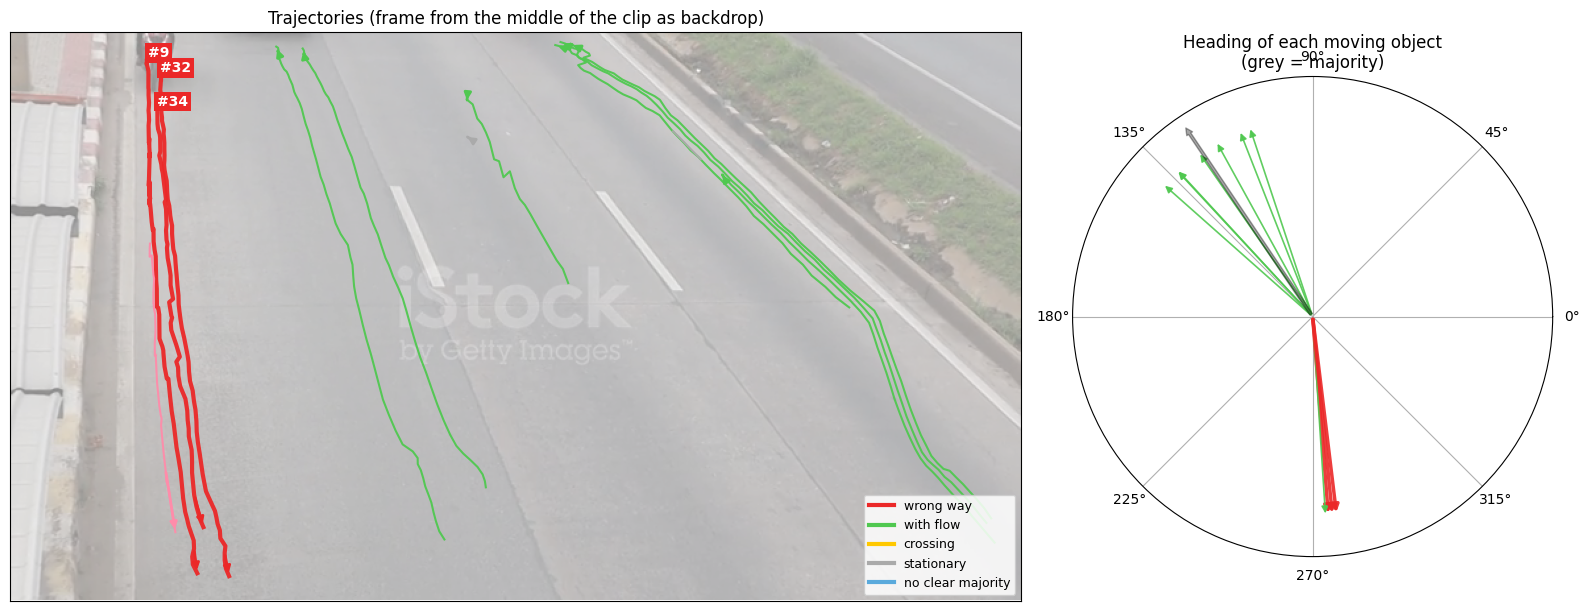

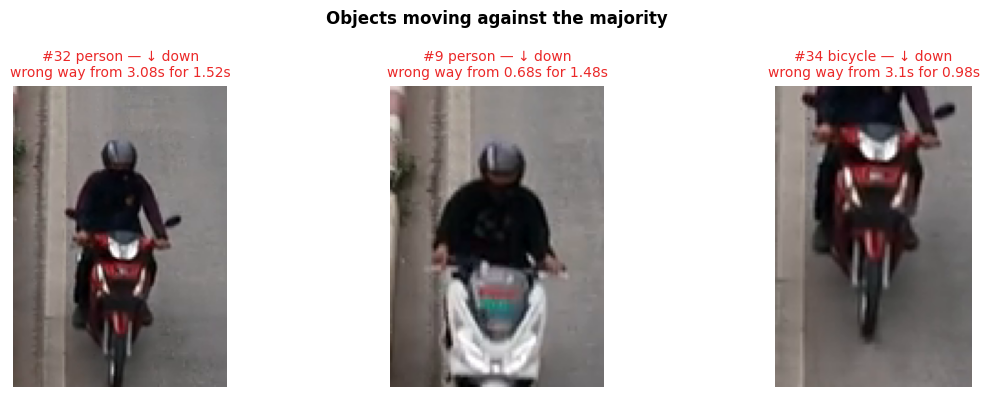

In [ ]:
#@title Trajectories, headings and snapshots of wrong-way objects

def read_frame(idx):
    cap = cv2.VideoCapture(VIDEO_FILE); cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
    ok, img = cap.read(); cap.release()
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if ok else np.zeros((H, W, 3), np.uint8)

MPL = {k: tuple(c / 255 for c in v[::-1]) for k, v in COLORS.items()}
fig = plt.figure(figsize=(16, 6.5))
ax = fig.add_subplot(1, 3, (1, 2))
ax.imshow(read_frame(N_PROCESSED // 2), alpha=0.45)
for tid, g in df.groupby("id"):
    if len(g) < 3:
        continue
    t = tracks.set_index("id").loc[tid]
    key = "wrong_way" if t.wrong_way else (g.state.mode()[0] if len(g) else "stationary")
    ax.plot(g.cx, g.cy, color=MPL[key], lw=3 if t.wrong_way else 1.5, alpha=0.95)
    if len(g) > 4:
        ax.annotate("", xy=(g.cx.iloc[-1], g.cy.iloc[-1]), xytext=(g.cx.iloc[-4], g.cy.iloc[-4]),
                    arrowprops=dict(arrowstyle="-|>", color=MPL[key], lw=2))
    if t.wrong_way:
        ax.text(g.cx.iloc[0], g.cy.iloc[0], f"#{tid}", color="white", fontsize=10, weight="bold",
                bbox=dict(facecolor=MPL["wrong_way"], edgecolor="none", pad=2))
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Trajectories (frame from the middle of the clip as backdrop)")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], color=MPL[k], lw=3, label=l) for k, l in
                   [("wrong_way", "wrong way"), ("with_flow", "with flow"), ("crossing", "crossing"),
                    ("stationary", "stationary"), ("no_majority", "no clear majority")]],
          loc="lower right", fontsize=9, framealpha=0.85)

# rose plot of each moving track's mean heading (up = up in the image)
axp = fig.add_subplot(1, 3, 3, projection="polar")
for tid, g in df[df.moving & df.ux.notna()].groupby("id"):
    v = g[["ux", "uy"]].mean().to_numpy()
    if np.linalg.norm(v) < 0.3:
        continue
    th = math.atan2(-v[1], v[0])
    bad = bool(tracks.set_index("id").loc[tid].wrong_way)
    axp.annotate("", xy=(th, 1), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", lw=2.5 if bad else 1.2,
                 color=MPL["wrong_way"] if bad else MPL["with_flow"], alpha=0.9))
fin = MAJ[np.isfinite(MAJ[:, 0])]
if len(fin):
    m = fin.mean(0)
    axp.annotate("", xy=(math.atan2(-m[1], m[0]), 1.15), xytext=(0, 0),
                 arrowprops=dict(arrowstyle="simple", color="black", alpha=0.35))
axp.set_ylim(0, 1.2); axp.set_yticks([]); axp.set_title("Heading of each moving object\n(grey = majority)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "trajectories.png"), dpi=120); plt.show()

if len(ww):
    show = ww.head(12)
    cols = min(4, len(show)); rows_ = math.ceil(len(show) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(4 * cols, 4 * rows_), squeeze=False)
    for ax, (_, t) in zip(axes.flat, show.iterrows()):
        g = df[(df.id == t.id) & df.wrong_way]
        r = g.iloc[len(g) // 2]
        img = read_frame(r.frame)
        pad = 0.25 * max(r.x2 - r.x1, r.y2 - r.y1)
        x1, y1 = int(max(r.x1 - pad, 0)), int(max(r.y1 - pad, 0))
        x2, y2 = int(min(r.x2 + pad, W)), int(min(r.y2 + pad, H))
        ax.imshow(img[y1:y2, x1:x2])
        ax.set_title(f"#{t.id} {t.cls} — {t.heading}\nwrong way from {t.wrong_way_from_s}s for {t.wrong_way_for_s}s",
                     fontsize=10, color=MPL["wrong_way"])
    for ax in axes.flat:
        ax.axis("off")
    plt.suptitle("Objects moving against the majority", weight="bold"); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "wrong_way_snapshots.png"), dpi=120); plt.show()
else:
    print("No object moved against the majority for long enough to be flagged.")

## Save and download
`detections.csv` has one row per object per frame (box, velocity, state); `tracks.csv` has one row per object.

In [ ]:
#@title Save outputs (and download a zip in Colab)
df.drop(columns=["sx", "sy"] if not COMPENSATE_CAMERA_MOTION else []).round(3).to_csv(os.path.join(OUT_DIR, "detections.csv"), index=False)
tracks.to_csv(os.path.join(OUT_DIR, "tracks.csv"), index=False)
zip_path = os.path.join(WORK_DIR, "wrong_way_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(OUT_DIR)):
        z.write(os.path.join(OUT_DIR, fn), fn)
print("Saved:", ", ".join(sorted(os.listdir(OUT_DIR))), "→", zip_path)
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

Saved: annotated.mp4, detections.csv, tracks.csv, trajectories.png, wrong_way_snapshots.png → /content/wrong_way_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Tuning tips and limitations

| Symptom | Try |
|---|---|
| Parked / standing objects get flagged | Raise `MIN_SPEED` (e.g. 0.4–0.6). |
| Slow or stop-and-go traffic flagged as wrong way | Raise `VEL_LAG_SEC` (1–1.5) and `MIN_OPPOSITE_DIST` (0.5–1), and use a larger model so IDs don't swap. |
| Real wrong-way objects are missed | Lower `OPPOSITE_ANGLE_DEG` (e.g. 120), lower `MIN_OPPOSITE_SEC`, or lower `CONF` so the object is tracked more continuously. |
| Brief false alarms when IDs swap in crowds | Raise `MIN_OPPOSITE_SEC` (e.g. 1.0), try `botsort.yaml`, or a larger model (`yolo26s/m`). |
| "No clear majority" | Two-way traffic is balanced — crop/limit the video to one lane or direction, or restrict `CLASSES`. |
| The main flow changes during the video | Set `MAJORITY_WINDOW_SEC` to e.g. 10–30 so the majority is recomputed over a sliding window. |
| Everything is flagged or nothing is | Camera is moving — turn on `COMPENSATE_CAMERA_MOTION`. |
| Slow | Use a GPU runtime, `IMGSZ = 480`, or `MAX_SECONDS` to test on a short piece first. |

**Limitations.** Directions are measured in the image plane, so motion straight toward/away from the camera is
foreshortened (a car driving toward a dashcam barely moves sideways). "Opposite" is relative to whatever most
objects in the scene are doing — on a two-way road, run it per lane or crop the video first. Camera-motion
compensation assumes the background is mostly static and dominates the frame.